In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Définition du dossier de travail
dossier_projet = Path("C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/projet_python_2a_ensae")

# ==============================================================================
# 1. Charger les contours des quartiers depuis votre fichier local 'iris.gpkg'
# ==============================================================================
print("Chargement des contours des quartiers...")
iris_all = gpd.read_file(dossier_projet / "iris.gpkg")

# Trouver la colonne qui contient les codes IRIS
col_geo_code = None
for col in iris_all.columns:
    sample = iris_all[col].astype(str).str.strip()
    if (sample.str.len() == 9).any() and sample.str.startswith('93').any():
        col_geo_code = col
        break

if col_geo_code is None:
    for c in ['CODE_IRIS', 'IRIS', 'code', 'DCODiIRIS']:
        if c in iris_all.columns:
            col_geo_code = c
            break

print(f"-> Colonne géographique IRIS identifiée : {col_geo_code}")

# Filtrer Saint-Ouen-sur-Seine (Code INSEE 93070)
st_ouen_iris = iris_all[iris_all[col_geo_code].astype(str).str.strip().str.startswith('93070')].copy()
st_ouen_iris[col_geo_code] = st_ouen_iris[col_geo_code].astype(str).str.strip().str.zfill(9)


# ==============================================================================
# 2. Charger et préparer les données de 2018
# ==============================================================================
print("Chargement du fichier INSEE 2018...")
file_2018 = dossier_projet / "BASE_TD_FILO_DISP_IRIS_2018.xlsx"
df_2018 = pd.read_excel(file_2018, skiprows=5)

col_iris_2018 = 'IRIS'
col_niv_2018 = 'DISP_MED18' if 'DISP_MED18' in df_2018.columns else [c for c in df_2018.columns if 'MED' in c][0]

df_2018[col_iris_2018] = df_2018[col_iris_2018].astype(str).str.strip().str.zfill(9)
df_2018[col_niv_2018] = pd.to_numeric(df_2018[col_niv_2018], errors='coerce')

# Fusion 2018
st_ouen_2018 = st_ouen_iris.merge(df_2018, left_on=col_geo_code, right_on=col_iris_2018, how='inner')


# ==============================================================================
# 3. Charger et préparer les données de 2021 (Sélection stricte du niveau de vie)
# ==============================================================================
print("Recherche et chargement du fichier INSEE 2021...")

fichiers_2021 = list(dossier_projet.glob("*2021*.xlsx")) + list(dossier_projet.glob("*2021*.XLSX"))
if not fichiers_2021:
    fichiers_2021 = list(dossier_projet.glob("*.xlsx"))

file_2021 = fichiers_2021[0]
print(f"-> Fichier 2021 détecté : {file_2021.name}")

df_2021 = pd.read_excel(file_2021, skiprows=5)

col_iris_2021 = 'IRIS' if 'IRIS' in df_2021.columns else df_2021.columns[0]

# Recherche ciblée : on cherche une colonne avec 'MED' ou 'DISP' et dont les valeurs moyennes sont réalistes (entre 10k et 40k)
col_niv_2021 = None
for c in df_2021.columns:
    if c == col_iris_2021:
        continue
    # Vérifie si le nom contient MED ou DISP
    if any(kw in str(c).upper() for kw in ['MED', 'DISP_MED']):
        s = pd.to_numeric(df_2021[c], errors='coerce')
        val_moy = s.dropna().mean()
        if 10000 <= val_moy <= 40000:
            col_niv_2021 = c
            break

# Si non trouvé par nom, on cherche par fourchette de valeurs réalistes pour un niveau de vie médian
if col_niv_2021 is None:
    for c in df_2021.columns:
        if c == col_iris_2021:
            continue
        s = pd.to_numeric(df_2021[c], errors='coerce')
        val_moy = s.dropna().mean()
        if 15000 <= val_moy <= 35000:
            col_niv_2021 = c
            break

if col_niv_2021 is None:
    raise ValueError("Impossible de trouver automatiquement la colonne de niveau de vie médian pour 2021.")

print(f"-> Colonne IRIS 2021 identifiée : {col_iris_2021}")
print(f"-> Colonne niveau de vie 2021 identifiée : {col_niv_2021}")

df_2021[col_iris_2021] = df_2021[col_iris_2021].astype(str).str.split('.').str[0].str.strip().str.zfill(9)
df_2021[col_niv_2021] = pd.to_numeric(df_2021[col_niv_2021], errors='coerce')

# Fusion 2021
st_ouen_2021 = st_ouen_iris.merge(df_2021, left_on=col_geo_code, right_on=col_iris_2021, how='inner')
print(f"-> Fusion 2021 réussie ! {len(st_ouen_2021)} quartiers appariés.")


# ==============================================================================
# 4. Générer les deux cartes côte à côte
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Carte 1 : 2018
st_ouen_2018.plot(
    ax=axes[0],
    column=col_niv_2018,
    cmap='YlOrRd',
    edgecolor='black',
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={'label': "Niveau de vie médian (€/an)", 'orientation': "horizontal", 'pad': 0.05}
)
axes[0].set_title("Saint-Ouen-sur-Seine - Niveau de vie (2018)", fontsize=13)
axes[0].axis('off')

# Carte 2 : 2021
st_ouen_2021.plot(
    ax=axes[1],
    column=col_niv_2021,
    cmap='YlOrRd',
    edgecolor='black',
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={'label': "Niveau de vie médian (€/an)", 'orientation': "horizontal", 'pad': 0.05}
)
axes[1].set_title("Saint-Ouen-sur-Seine - Niveau de vie (2021)", fontsize=13)
axes[1].axis('off')

plt.tight_layout()
plt.show()

Chargement des contours des quartiers...
-> Colonne géographique IRIS identifiée : code_iris
Chargement du fichier INSEE 2018...


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\pauli_ubewzsu\\OneDrive\\Bureau\\python 2a\\projet_python_2a_ensae\\BASE_TD_FILO_DISP_IRIS_2018.xlsx'

Chargement des contours des quartiers...


C:\Users\pauli_ubewzsu\AppData\Local\Temp\ipykernel_20524\4012721659.py:104: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["part_cadres"] = (df[col_cadres] / df[col_total]) * 100
c:\Users\pauli_ubewzsu\OneDrive\Bureau\python 2a\.venv\lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\pauli_ubewzsu\AppData\Local\Temp\ipykernel_20524\4012721659.py:136: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["mixité_sociale"] = 

Fusion réussie -> IRIS 2011 : 18 | IRIS 2021 : 18


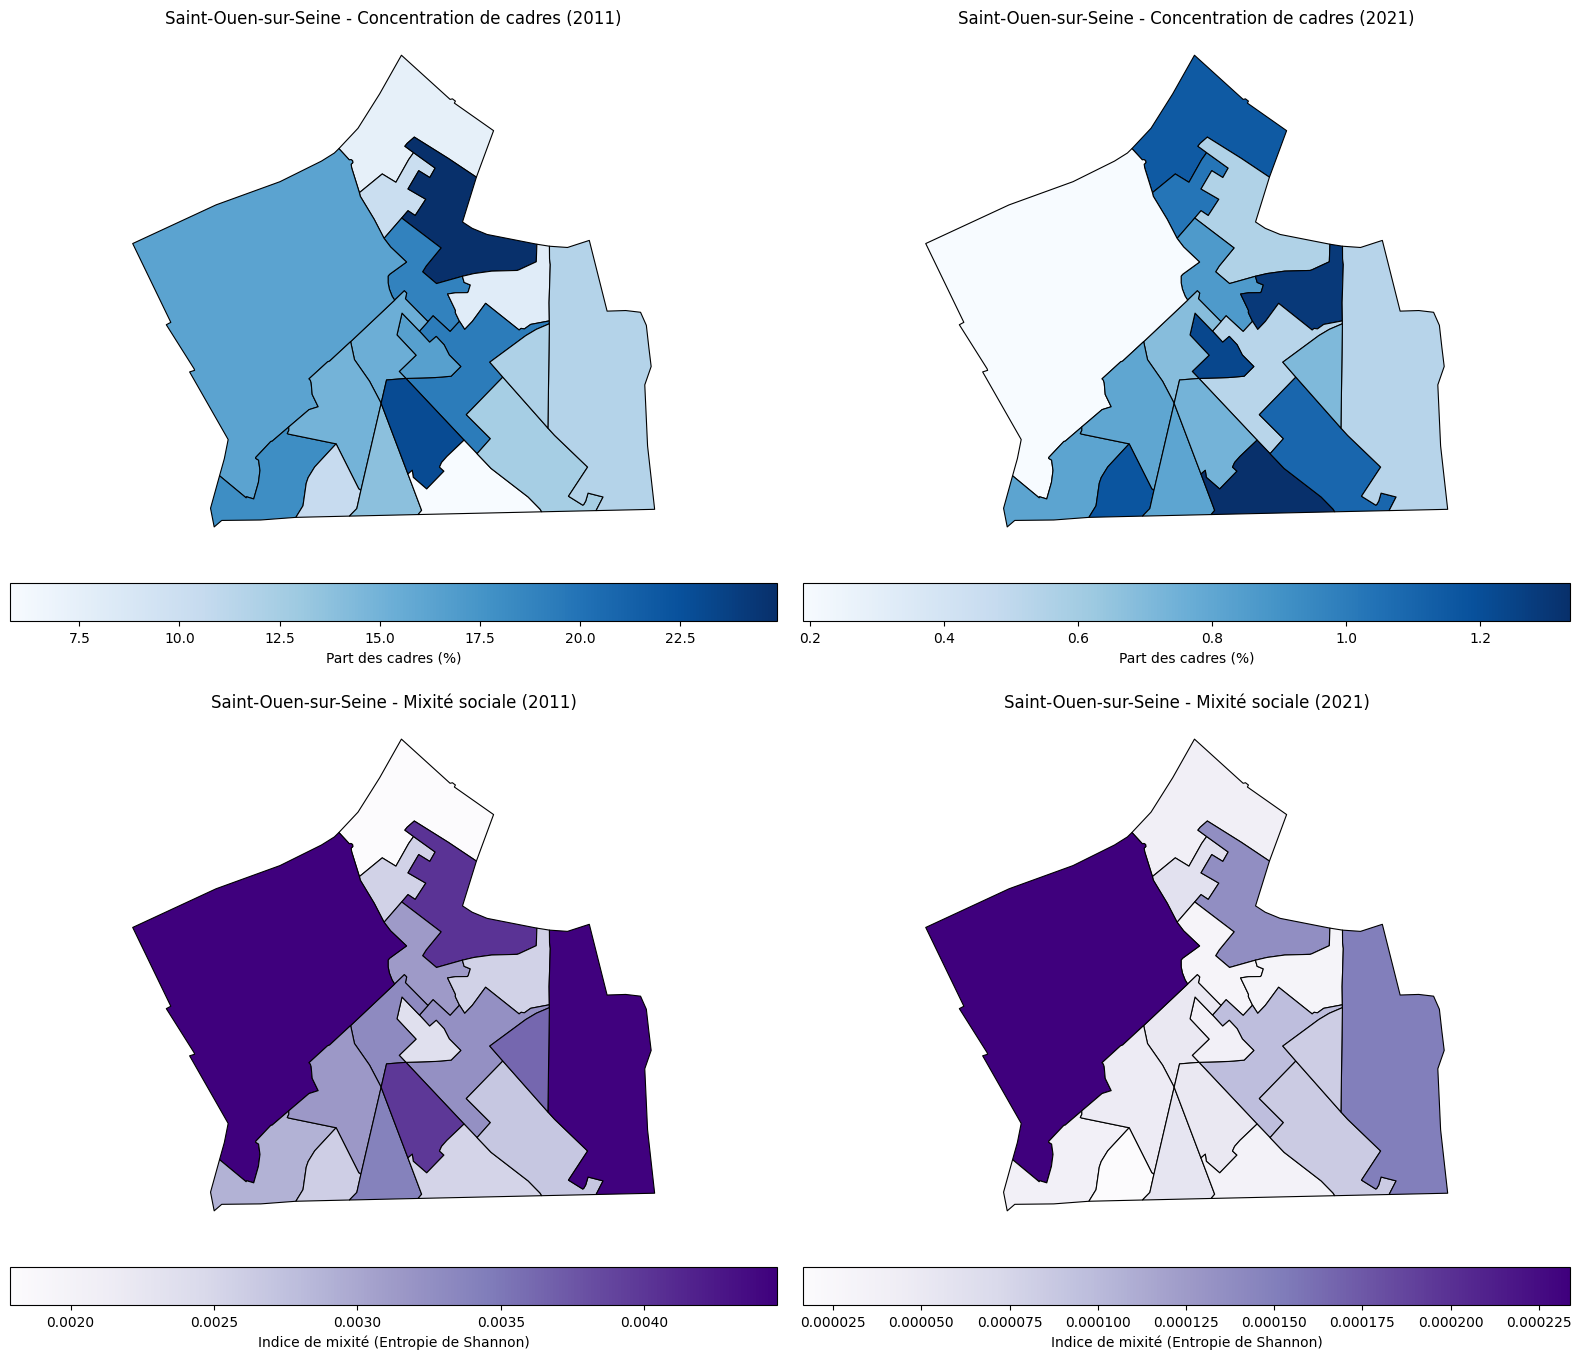

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CHARGEMENT ET PRÉPARATION DU FONDS DE CARTE (SAINT-OUEN)
# ==============================================================================
print("Chargement des contours des quartiers...")
iris_all = gpd.read_file(
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/projet_python_2a_ensae/iris.gpkg"
)

# Trouver la colonne géographique
col_geo_code = None
for col in iris_all.columns:
  sample = iris_all[col].astype(str).str.strip()
  if (sample.str.len() == 9).any() and sample.str.startswith("93").any():
    col_geo_code = col
    break

if col_geo_code is None:
  for c in ["CODE_IRIS", "IRIS", "code", "DCODiIRIS"]:
    if c in iris_all.columns:
      col_geo_code = c
      break

# Filtrer Saint-Ouen-sur-Seine (Code INSEE 93070)
st_ouen_iris = iris_all[
    iris_all[col_geo_code].astype(str).str.strip().str.startswith("93070")
].copy()

# Création d'une clé textuelle propre sur 9 caractères pour le fonds de carte
st_ouen_iris["merge_key"] = (
    st_ouen_iris[col_geo_code]
    .astype(str)
    .str.split(".")
    .str[0]
    .str.strip()
    .str.zfill(9)
)


# ==============================================================================
# 2. CHARGEMENT ET NETTOYAGE DES DONNÉES INFORMATIVES (CSP 2011 & 2021)
# ==============================================================================
file_2011 = "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-activite-residents-2011.xls"
file_2021 = "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-activite-residents-2022.xlsx"

df_2011 = pd.read_excel(file_2011, skiprows=5)
df_2021 = pd.read_excel(file_2021, skiprows=5)

# Normalisation et création de la même clé textuelle pour les tableaux INSEE
for df in [df_2011, df_2021]:
  col_iris_name = next(
      (c for c in df.columns if "IRIS" in c.upper() or "CODE" in c.upper()),
      df.columns[0],
  )
  df["merge_key"] = (
      df[col_iris_name]
      .astype(str)
      .str.split(".")
      .str[0]
      .str.strip()
      .str.zfill(9)
  )


# ==============================================================================
# 3. CALCUL DES INDICATEURS (Part des cadres & Indice de Shannon)
# ==============================================================================
def preparer_donnees_csp(df):
  cols_num = [c for c in df.columns if c != "merge_key"]
  for c in cols_num:
    df[c] = pd.to_numeric(df[c], errors="coerce")
  return df


df_2011 = preparer_donnees_csp(df_2011)
df_2021 = preparer_donnees_csp(df_2021)


def calcul_indicateurs(df):
  # Détection dynamique des colonnes clés de l'INSEE
  col_cadres = next(
      (
          c
          for c in df.columns
          if "CADRE" in c.upper() or "CS3" in c.upper()
      ),
      df.columns[1],
  )
  col_total = next(
      (
          c
          for c in df.columns
          if "ACT15P" in c.upper()
          or ("ACT" in c.upper() and "15" in c.upper())
      ),
      df.columns[3],
  )

  # 1. Calcul de la part des cadres (%)
  df["part_cadres"] = (df[col_cadres] / df[col_total]) * 100

  # 2. Calcul du véritable Indice de Mixité Sociale (Entropie de Shannon)
  csp_keywords = [
      "AGRI",
      "ART",
      "CADRE",
      "PROF",
      "EMP",
      "OUV",
      "CS1",
      "CS2",
      "CS3",
      "CS4",
      "CS5",
      "CS6",
  ]
  cols_csp = [
      c
      for c in df.columns
      if any(kw in c.upper() for kw in csp_keywords)
      and c != col_total
      and c != "merge_key"
  ]

  if len(cols_csp) >= 2:
    somme_csp = df[cols_csp].sum(axis=1).replace(0, np.nan)
    shannon_index = 0
    for c in cols_csp:
      p_i = df[c] / somme_csp
      # Formule de Shannon : - sum(p_i * ln(p_i))
      shannon_index -= np.where(p_i > 0, p_i * np.log(p_i), 0)
    df["mixité_sociale"] = shannon_index
  else:
    df["mixité_sociale"] = 0.0

  return df


df_2011 = calcul_indicateurs(df_2011)
df_2021 = calcul_indicateurs(df_2021)

# Fusion ultra-sécurisée via la clé commune 'merge_key'
st_ouen_2011 = st_ouen_iris.merge(df_2011, on="merge_key", how="inner")
st_ouen_2021 = st_ouen_iris.merge(df_2021, on="merge_key", how="inner")

print(
    f"Fusion réussie -> IRIS 2011 : {len(st_ouen_2011)} | IRIS 2021 :"
    f" {len(st_ouen_2021)}"
)


# ==============================================================================
# 4. GÉNÉRATION DES 4 CARTES (2x2)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# --- Carte 1 : Part des cadres (2011) ---
st_ouen_2011.plot(
    ax=axes[0, 0],
    column="part_cadres",
    cmap="Blues",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des cadres (%)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[0, 0].set_title(
    "Saint-Ouen-sur-Seine - Concentration de cadres (2011)", fontsize=12
)
axes[0, 0].axis("off")

# --- Carte 2 : Part des cadres (2021) ---
st_ouen_2021.plot(
    ax=axes[0, 1],
    column="part_cadres",
    cmap="Blues",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des cadres (%)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[0, 1].set_title(
    "Saint-Ouen-sur-Seine - Concentration de cadres (2021)", fontsize=12
)
axes[0, 1].axis("off")

# --- Carte 3 : Mixité sociale (2011) ---
st_ouen_2011.plot(
    ax=axes[1, 0],
    column="mixité_sociale",
    cmap="Purples",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Indice de mixité (Entropie de Shannon)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[1, 0].set_title(
    "Saint-Ouen-sur-Seine - Mixité sociale (2011)", fontsize=12
)
axes[1, 0].axis("off")

# --- Carte 4 : Mixité sociale (2021) ---
st_ouen_2021.plot(
    ax=axes[1, 1],
    column="mixité_sociale",
    cmap="Purples",
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Indice de mixité (Entropie de Shannon)",
        "orientation": "horizontal",
        "pad": 0.05,
    },
)
axes[1, 1].set_title(
    "Saint-Ouen-sur-Seine - Mixité sociale (2021)", fontsize=12
)
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

--- Colonnes détectées (11) ---
  Total ménages        : C11_MEN
  Jeunes seuls         : P11_POP1524_PSEUL
  Couples sans enfant  : C11_MENCOUPSENF (spécifique jeune: None)
--- Colonnes détectées (22) ---
  Total ménages        : C22_MEN
  Jeunes seuls         : P22_POP1524_PSEUL
  Couples sans enfant  : C22_MENCOUPSENF (spécifique jeune: None)
IRIS Saint-Ouen : 18 | Sans valeur 2011 : 0 | Sans valeur 2022 : 0


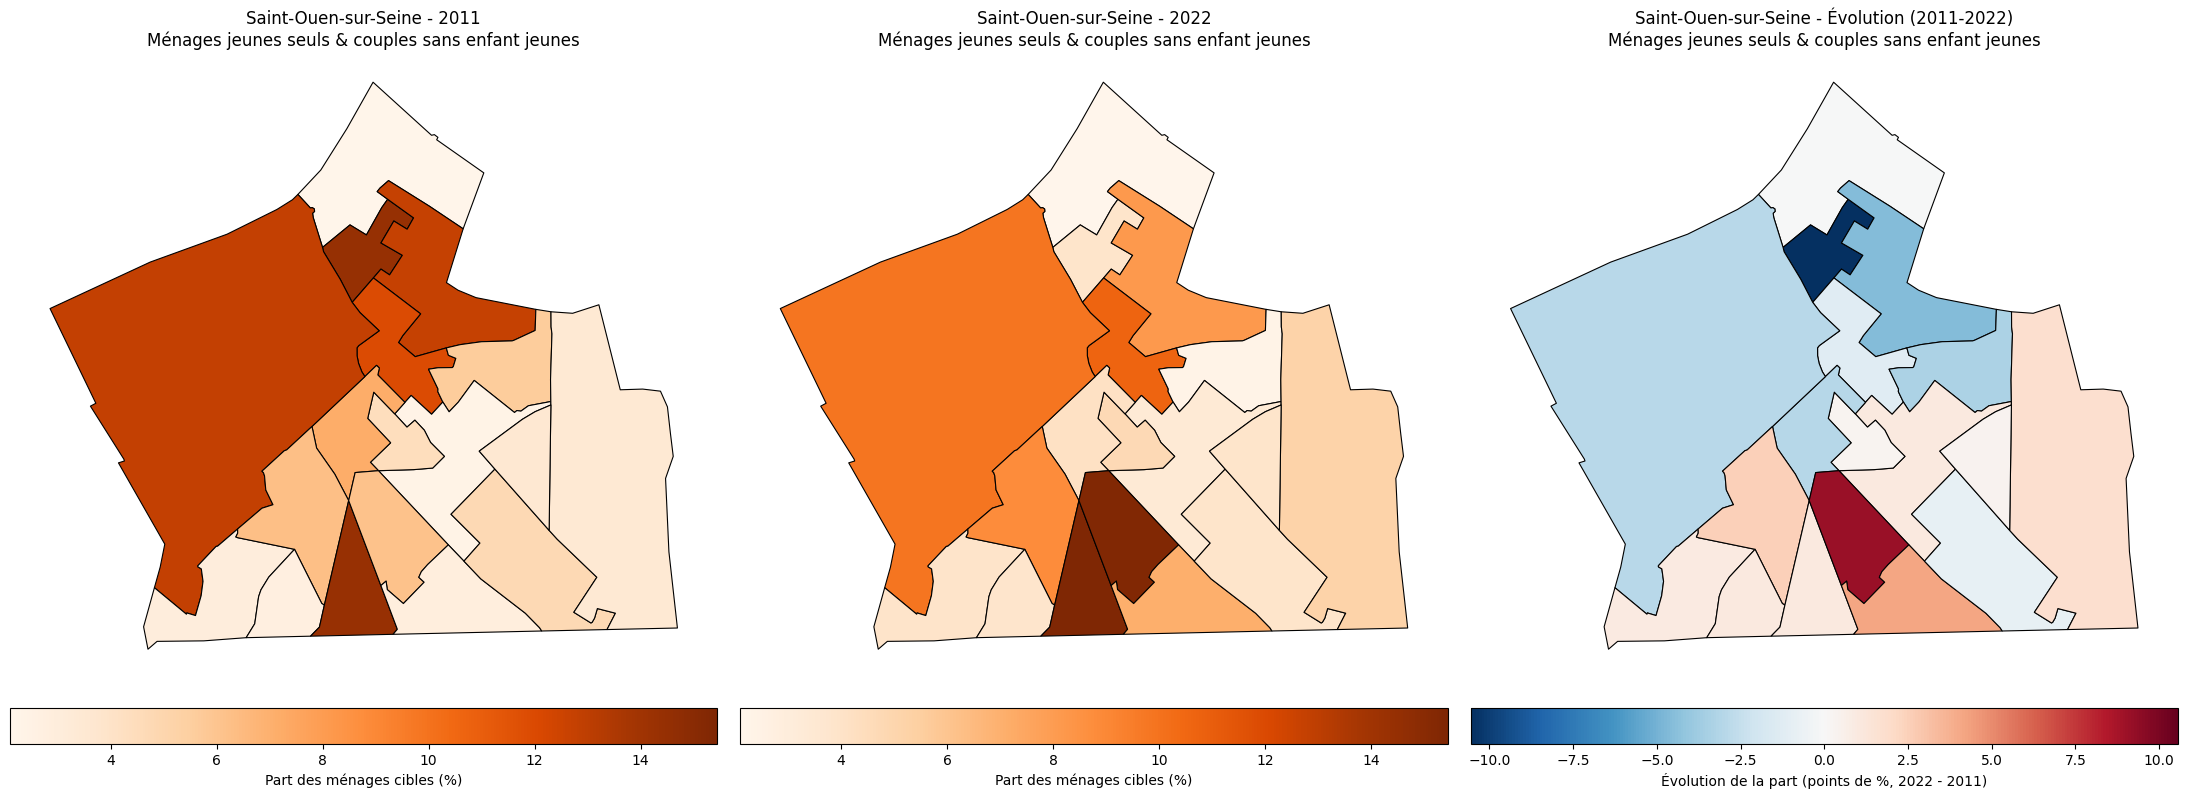

In [ ]:
# ==============================================================================
# 5. ÉVOLUTION 2011 - 2022 : JEUNES MÉNAGES SEULS & COUPLES SANS ENFANT JEUNES
#    (Base INSEE : Couples - Familles - Ménages)
# ==============================================================================
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

file_cfm_2011 = (
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-couples-familles-menages-2011.xls"
)
file_cfm_2022 = (
    "C:/Users/pauli_ubewzsu/OneDrive/Bureau/python 2a/base-ic-couples-familles-menages-2022.xlsx"
)


def trouver_colonne(df, candidats, mots_cles_fallback=None):
  cols_upper = {str(c).upper(): c for c in df.columns}
  # 1. Recherche exacte
  for cand in candidats:
    c_up = cand.upper()
    if c_up in cols_upper:
      return cols_upper[c_up]
  # 2. Recherche partielle
  for cand in candidats:
    c_up = cand.upper()
    for up, orig in cols_upper.items():
      if c_up in up:
        return orig
  # 3. Recherche souple par mots-clés
  if mots_cles_fallback:
    for up, orig in cols_upper.items():
      if all(k.upper() in up for k in mots_cles_fallback):
        return orig
  return None


def normaliser_code_iris(serie):
  return (
      serie.astype(str)
      .str.replace(r"\.0$", "", regex=True)
      .str.strip()
      .str.zfill(9)
  )


def preparer_fonds_carte_st_ouen(gdf):
  """Garantit la présence d'une colonne 'merge_key' propre sur le GeoDataFrame."""
  out = gdf.copy()
  if "merge_key" not in out.columns:
    col_iris = trouver_colonne(
        out,
        ["CODE_IRIS", "IRIS", "ID_IRIS", "DCOMIRIS", "CODE"],
        mots_cles_fallback=["IRIS"],
    )
    if col_iris is None:
      raise KeyError(
          f"Impossible de trouver la colonne IRIS dans st_ouen_iris. Colonnes disponibles : {list(out.columns)}"
      )
    print(f"Colonne IRIS détectée dans st_ouen_iris : '{col_iris}'")
    out["merge_key"] = normaliser_code_iris(out[col_iris])
  else:
    out["merge_key"] = normaliser_code_iris(out["merge_key"])
  return out.drop_duplicates(subset=["merge_key"], keep="first")


def charger_cfm(chemin_fichier):
  df = pd.read_excel(chemin_fichier, skiprows=5)
  col_iris_cfm = trouver_colonne(
      df,
      ["IRIS", "CODE_IRIS", "COM", "GEO"],
      mots_cles_fallback=["IRIS"],
  )
  if col_iris_cfm is None:
    col_iris_cfm = df.columns[0]

  df["merge_key"] = normaliser_code_iris(df[col_iris_cfm])
  for c in df.columns:
    if c != "merge_key":
      df[c] = pd.to_numeric(df[c], errors="coerce")
  return df.drop_duplicates(subset=["merge_key"], keep="first")


def preparer_indicateur_jeunes_menages(df, annee_court):
  """Calcule l'effectif et la part (%) des ménages jeunes seuls et couples sans enfant jeunes."""
  col_men_total = trouver_colonne(
      df,
      [f"C{annee_court}_MEN", "MEN", "P_MEN"],
      mots_cles_fallback=["MEN"],
  )
  if col_men_total is None:
    raise KeyError(
        f"Colonne total ménages introuvable pour {annee_court}. Colonnes : {list(df.columns[:15])}"
    )

  col_jeunes_seuls = trouver_colonne(
      df,
      [
          f"P{annee_court}_POP1524_PSEUL",
          f"C{annee_court}_MENPSEUL_1524",
          "POP1524_PSEUL",
          "MENPSEUL",
      ],
  )
  col_couples_sans_enf = trouver_colonne(
      df,
      [
          f"C{annee_court}_MENCOUPSENF",
          f"C{annee_court}_MEN1FCOUPSENF",
          "MENCOUPSENF",
          "COUPSENF",
      ],
  )
  col_couples_jeunes = trouver_colonne(
      df,
      [
          f"C{annee_court}_MENCOUPSENF_JEUNE",
          "COUPSENF_JEUNE",
          "COUPLE_JEUNE",
      ],
  )

  print(f"--- Colonnes détectées ({annee_court}) ---")
  print(f"  Total ménages        : {col_men_total}")
  print(f"  Jeunes seuls         : {col_jeunes_seuls}")
  print(
      f"  Couples sans enfant  : {col_couples_sans_enf} (spécifique jeune: {col_couples_jeunes})"
  )

  effectif_jeunes_seuls = (
      df[col_jeunes_seuls].fillna(0) if col_jeunes_seuls else 0.0
  )

  if col_couples_jeunes:
    effectif_couples = df[col_couples_jeunes].fillna(0)
  elif col_couples_sans_enf:
    col_pop_jeunes = trouver_colonne(df, [f"P{annee_court}_POP1524", "POP1524"])
    col_pop_tot = trouver_colonne(
        df, [f"P{annee_court}_POP15P", "POP15P", f"P{annee_court}_POP"]
    )
    if col_pop_jeunes and col_pop_tot:
      part_jeunes_pop = (
          df[col_pop_jeunes] / df[col_pop_tot].replace(0, np.nan)
      ).fillna(0)
      effectif_couples = df[col_couples_sans_enf].fillna(0) * part_jeunes_pop
    else:
      effectif_couples = df[col_couples_sans_enf].fillna(0)
  else:
    effectif_couples = 0.0

  out = pd.DataFrame({
      "merge_key": df["merge_key"],
      "nb_cible": effectif_jeunes_seuls + effectif_couples,
      "nb_men_total": df[col_men_total],
  })
  out["part_cible_pct"] = (
      out["nb_cible"] / out["nb_men_total"].replace(0, np.nan)
  ) * 100
  return out


st_ouen_clean = preparer_fonds_carte_st_ouen(st_ouen_iris)
cfm_2011 = charger_cfm(file_cfm_2011)
cfm_2022 = charger_cfm(file_cfm_2022)

ind_2011 = preparer_indicateur_jeunes_menages(cfm_2011, "11")
ind_2022 = preparer_indicateur_jeunes_menages(cfm_2022, "22")

# Fusion avec le fonds de carte de Saint-Ouen
evol_iris = (
    st_ouen_clean[["merge_key", "geometry"]]
    .merge(
        ind_2011[["merge_key", "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2011", "part_cible_pct": "part_2011"}
        ),
        on="merge_key",
        how="left",
    )
    .merge(
        ind_2022[["merge_key", "nb_cible", "part_cible_pct"]].rename(
            columns={"nb_cible": "nb_2022", "part_cible_pct": "part_2022"}
        ),
        on="merge_key",
        how="left",
    )
)

# Évolution en points de pourcentage (2022 - 2011)
evol_iris["evol_pts"] = evol_iris["part_2022"] - evol_iris["part_2011"]

print(
    f"IRIS Saint-Ouen : {len(evol_iris)} | "
    f"Sans valeur 2011 : {evol_iris['part_2011'].isna().sum()} | "
    f"Sans valeur 2022 : {evol_iris['part_2022'].isna().sum()}"
)

# Bornes communes pour les cartes 2011 et 2022
vals_parts = pd.concat(
    [evol_iris["part_2011"], evol_iris["part_2022"]], ignore_index=True
).dropna()
vmin_part = float(vals_parts.min()) if not vals_parts.empty else 0.0
vmax_part = float(vals_parts.max()) if not vals_parts.empty else 10.0
if vmin_part == vmax_part:
  vmax_part = vmin_part + 1.0

# Borne symétrique autour de 0 pour la carte d'évolution
vmax_evol = np.nanmax(np.abs(evol_iris["evol_pts"]))
vmax_evol = float(vmax_evol) if pd.notna(vmax_evol) and vmax_evol > 0 else 5.0

fig_3cartes, axes = plt.subplots(1, 3, figsize=(22, 8))

# --- Carte 1 : 2011 ---
evol_iris.plot(
    ax=axes[0],
    column="part_2011",
    cmap="Oranges",
    vmin=vmin_part,
    vmax=vmax_part,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des ménages cibles (%)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[0].set_title(
    "Saint-Ouen-sur-Seine - 2011\n"
    "Ménages jeunes seuls & couples sans enfant jeunes",
    fontsize=12,
)
axes[0].axis("off")

# --- Carte 2 : 2022 ---
evol_iris.plot(
    ax=axes[1],
    column="part_2022",
    cmap="Oranges",
    vmin=vmin_part,
    vmax=vmax_part,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Part des ménages cibles (%)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[1].set_title(
    "Saint-Ouen-sur-Seine - 2022\n"
    "Ménages jeunes seuls & couples sans enfant jeunes",
    fontsize=12,
)
axes[1].axis("off")

# --- Carte 3 : Évolution 2022 - 2011 ---
evol_iris.plot(
    ax=axes[2],
    column="evol_pts",
    cmap="RdBu_r",  # Rouge = hausse, Bleu = baisse
    vmin=-vmax_evol,
    vmax=vmax_evol,
    edgecolor="black",
    linewidth=0.8,
    legend=True,
    missing_kwds={"color": "lightgrey", "edgecolor": "black", "hatch": "///"},
    legend_kwds={
        "label": "Évolution de la part (points de %, 2022 - 2011)",
        "orientation": "horizontal",
        "pad": 0.04,
    },
)
axes[2].set_title(
    "Saint-Ouen-sur-Seine - Évolution (2011-2022)\n"
    "Ménages jeunes seuls & couples sans enfant jeunes",
    fontsize=12,
)
axes[2].axis("off")

plt.tight_layout()
plt.show()